<a href="https://colab.research.google.com/github/SUNHO0825/TIL/blob/main/%5B%EB%8D%B0%EC%9D%B4%ED%84%B0_%EC%A0%84%EC%B2%98%EB%A6%AC_%26_%EC%8B%9C%EA%B0%81%ED%99%94%5D_%EA%B3%BC%EC%A0%9C_%EC%9E%84%EC%84%A0%ED%98%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 문제 1. CSV 파일 읽기, 기본 정보 확인

In [224]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [225]:
booking_raw = pd.read_csv('/content/hotel_bookings.csv')
print(booking_raw.shape)

(300, 10)


In [226]:
booking_raw.head()

,booking_id,lead_time,weekend_nights,weekday_nights,adults,children,room_type,daily_rate,booking_channel,is_canceled
0,HB0204,15.0,2.0,5.0,2.0,1.0,Deluxe,180000.0,Direct,0
1,HB0267,7.0,0.0,4.0,2.0,0.0,Standard,130000.0,Direct,0
2,HB0153,28.0,2.0,4.0,1.0,0.0,Standard,70000.0,Online,0
3,HB0010,30.0,2.0,3.0,2.0,2.0,Standard,130000.0,Online,0
4,HB0234,171.0,0.0,4.0,2.0,1.0,Standard,120000.0,Agency,0


In [227]:
booking_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   booking_id       300 non-null    object 
 1   lead_time        298 non-null    float64
 2   weekend_nights   298 non-null    float64
 3   weekday_nights   298 non-null    float64
 4   adults           298 non-null    float64
 5   children         298 non-null    float64
 6   room_type        296 non-null    object 
 7   daily_rate       296 non-null    float64
 8   booking_channel  296 non-null    object 
 9   is_canceled      300 non-null    int64  
dtypes: float64(6), int64(1), object(3)
memory usage: 23.6+ KB


In [228]:
booking_raw.describe()

,lead_time,weekend_nights,weekday_nights,adults,children,daily_rate,is_canceled
count,298.000000,298.000000,298.000000,298.000000,298.000000,296.000000,300.000000
mean,47.677852,0.942953,2.953020,1.768456,0.422819,166587.837838,0.233333
std,51.739801,0.812425,1.448722,0.605873,0.683438,137061.828387,0.423659
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-10000.000000,0.000000
25%,8.000000,0.000000,2.000000,1.000000,0.000000,100000.000000,0.000000
50%,23.000000,1.000000,3.000000,2.000000,0.000000,120000.000000,0.000000
75%,78.750000,2.000000,4.000000,2.000000,1.000000,180000.000000,0.000000
max,179.000000,2.000000,5.000000,3.000000,2.000000,1000000.000000,1.000000


In [229]:
missing = pd.DataFrame({
    '결측치 개수': booking_raw.isna().sum(),
    '결측률(%)': (booking_raw.isna().mean() * 100).round(2),
})
missing

,결측치 개수,결측률(%)
booking_id,0,0.00
lead_time,2,0.67
weekend_nights,2,0.67
weekday_nights,2,0.67
adults,2,0.67
children,2,0.67
room_type,4,1.33
daily_rate,4,1.33
booking_channel,4,1.33
is_canceled,0,0.00


In [230]:
cancel_counts = booking_raw["is_canceled"].value_counts()
cancel_ratio = (booking_raw["is_canceled"].value_counts(normalize=True) * 100).round(2)
pd.DataFrame({"건수": cancel_counts, "비율(%)": cancel_ratio})

,건수,비율(%)
is_canceled,,
0,230,76.67
1,70,23.33


명확한 오류: lead_time, weekend_nights, weekday_nights, adults, children에 음수(−1)가 있고, daily_rate에 0 이하 값(−10,000)이 있다. 일수·인원수는 음수일 수 없고 요금은 0보다 커야 하므로 오류다.

결측치: 8개 열에 결측치가 있다. 수치형 5개 열은 각 2개, room_type·daily_rate·booking_channel은 각 4개다. children의 결측은 '어린이 0명'이 아니므로 0으로 채우면 안 된다.

확인이 필요한 값: daily_rate 최댓값 1,000,000원은 객실 유형에 따라 정상일 수 있어서 오류인지 따로 확인해야 한다.

# 문제 2. 결측치와 명확한 오류 값 처리

In [231]:
booking_clean = booking_raw.copy()
print(booking_clean.shape)

(300, 10)


In [232]:
num_cols = ['lead_time', 'weekend_nights', 'weekday_nights', 'adults', 'children']

neg_mask = (booking_clean[num_cols]<0).any(axis=1)
print(neg_mask.sum())

5


In [233]:
print(booking_clean.loc[neg_mask, ['booking_id'] + num_cols])

    booking_id  lead_time  weekend_nights  weekday_nights  adults  children
25      HB0043        6.0             2.0            -1.0     3.0       1.0
173     HB0042       27.0            -1.0             1.0     2.0       0.0
216     HB0045       74.0             2.0             2.0     2.0      -1.0
219     HB0041       -1.0             2.0             3.0     1.0       1.0
243     HB0044       29.0             0.0             5.0    -1.0       0.0


In [234]:
rate_mask = booking_clean['daily_rate'] <= 0
print(rate_mask.sum())
print(booking_clean.loc[rate_mask, ['booking_id', 'daily_rate']])

2
   booking_id  daily_rate
13     HB0046    -10000.0
38     HB0047         0.0


In [235]:
for col in num_cols:
    booking_clean.loc[booking_clean[col] < 0, col] = np.nan

print(booking_clean[num_cols].isna().sum())

lead_time         3
weekend_nights    3
weekday_nights    3
adults            3
children          3
dtype: int64


In [236]:
booking_clean.loc[rate_mask, 'daily_rate'] = np.nan

print(booking_clean['daily_rate'].isna().sum())
print(booking_clean.loc[rate_mask, ['booking_id', 'daily_rate']])   # HB0046, HB0047이 NaN이어야 함
print(booking_clean.shape)                                          # (300, 10)이어야 함

6
   booking_id  daily_rate
13     HB0046         NaN
38     HB0047         NaN
(300, 10)


In [237]:
before = len(booking_clean)

booking_clean = booking_clean.dropna(subset=num_cols)

after = len(booking_clean)
print('처리 전:', before, '처리 후:', after, '제외:', before - after)

처리 전: 300 처리 후: 285 제외: 15


In [238]:
print('평균:', booking_clean['daily_rate'].mean())
print('중앙값:', booking_clean['daily_rate'].median())
#daily_rate 대체값: 중앙값(120,000원). 평균(약 167,957원)은 Suite 같은 고가 예약의 영향으로 위로 치우쳐 있다. 중앙값은 극단적인 값의 영향을 덜 받아서, 대부분의 예약이 모여 있는 일반적인 요금을 더 잘 나타낸다.

평균: 167956.98924731184
중앙값: 120000.0


In [239]:
rate_median = booking_clean['daily_rate'].median()

booking_clean['daily_rate'] = booking_clean['daily_rate'].fillna(rate_median)

print(booking_clean['daily_rate'].isna().sum())

0


In [240]:
cat_cols = ['room_type', 'booking_channel']

booking_clean[cat_cols] = booking_clean[cat_cols].fillna('Unknown')

print(booking_clean[cat_cols].isna().sum())
print(booking_clean['room_type'].value_counts())
print(booking_clean['booking_channel'].value_counts())

room_type          0
booking_channel    0
dtype: int64
room_type
Standard    190
Deluxe       66
Suite        25
Unknown       4
Name: count, dtype: int64
booking_channel
Online     144
Direct      84
Agency      53
Unknown      4
Name: count, dtype: int64


In [241]:
print('처리 전 행 수:', before)
print('처리 후 행 수:', len(booking_clean))
print('제외한 행 수:', before - len(booking_clean))
print('남은 결측치 개수:', booking_clean.isna().sum().sum())

print('음수 일수·인원수 개수:', (booking_clean[num_cols] < 0).sum().sum())
print('0 이하 요금 개수:', (booking_clean['daily_rate'] <= 0).sum())

처리 전 행 수: 300
처리 후 행 수: 285
제외한 행 수: 15
남은 결측치 개수: 0
음수 일수·인원수 개수: 0
0 이하 요금 개수: 0


일수·인원수의 결측을 0이나 평균 같은 임의의 값으로 채우면 total_nights, total_guests가 실제와 달라진다. 예를 들어 어린이가 실제로 2명인데 0으로 채우면 동반 인원이 2명 적게 계산되고, 평균으로 채우면 2.42명처럼 존재할 수 없는 인원이 생긴다. 그래서 이 다섯 열에 결측이 있는 행은 제외했다.

room_type, booking_channel의 결측을 가장 많은 값으로 채우면 실제와 다른 객실 유형·경로가 기록되어 집단별 예약 수와 취소율이 왜곡될 수 있다. 그래서 'Unknown'으로 표시해 정보가 없다는 사실을 남기고, 같은 예약의 다른 정상 값은 분석에 그대로 사용했다.

#문제 3. 객실 요금의 이상치 후보 탐지 및 처리

In [242]:
q1 = booking_clean['daily_rate'].quantile(0.25)
q3 = booking_clean['daily_rate'].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print('Q1:', q1, ' Q3:', q3, ' IQR:', iqr)
print('하한:', lower, ' 상한:', upper)

Q1: 100000.0  Q3: 180000.0  IQR: 80000.0
하한: -20000.0  상한: 300000.0


In [243]:
outlier_mask = (booking_clean['daily_rate'] < lower) | (booking_clean['daily_rate'] > upper)

print('이상치 후보 건수:', outlier_mask.sum())
print('비율(%):', round(outlier_mask.mean() * 100, 2))
print(booking_clean.loc[outlier_mask, ['booking_id', 'room_type', 'daily_rate']])

이상치 후보 건수: 26
비율(%): 9.12
    booking_id room_type  daily_rate
7       HB0110     Suite    550000.0
8       HB0006     Suite    450000.0
14      HB0183     Suite    350000.0
32      HB0034     Suite    640000.0
37      HB0091     Suite    800000.0
57      HB0093     Suite   1000000.0
67      HB0257     Suite    420000.0
81      HB0155     Suite    560000.0
85      HB0115     Suite    480000.0
98      HB0275     Suite    580000.0
104     HB0266     Suite    580000.0
121     HB0173     Suite    480000.0
127     HB0126     Suite    390000.0
144     HB0211     Suite    600000.0
153     HB0159     Suite    610000.0
171     HB0209     Suite    400000.0
198     HB0028   Unknown    480000.0
199     HB0220     Suite    440000.0
244     HB0218     Suite    600000.0
252     HB0134     Suite    490000.0
256     HB0050     Suite    350000.0
258     HB0206     Suite    550000.0
260     HB0092     Suite    900000.0
267     HB0135     Suite    560000.0
270     HB0055     Suite    420000.0
290     HB00

In [244]:
print(booking_clean.groupby('room_type')['daily_rate'].agg(['count', 'min', 'median', 'max']))

           count       min    median        max
room_type                                      
Deluxe        66  120000.0  195000.0   250000.0
Standard     190   70000.0  110000.0   140000.0
Suite         25  350000.0  550000.0  1000000.0
Unknown        4  140000.0  210000.0   480000.0


In [245]:
booking_clean['daily_rate_processed'] = booking_clean['daily_rate']

print(booking_clean[['daily_rate', 'daily_rate_processed']].agg(['min', 'median', 'max']))

        daily_rate  daily_rate_processed
min        70000.0               70000.0
median    120000.0              120000.0
max      1000000.0             1000000.0


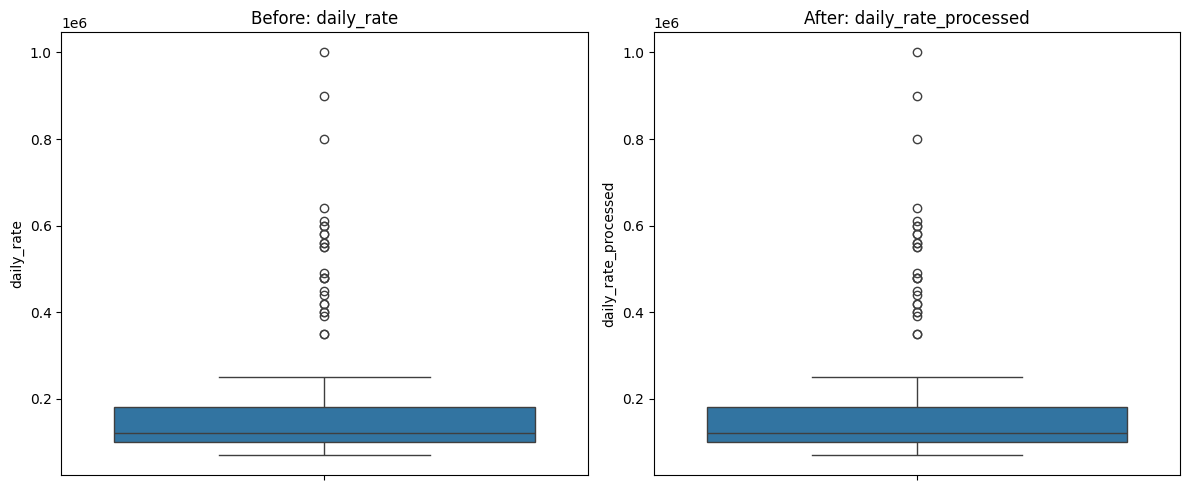

In [246]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=booking_clean['daily_rate'], ax=axes[0])
axes[0].set_title('Before: daily_rate')

sns.boxplot(y=booking_clean['daily_rate_processed'], ax=axes[1])
axes[1].set_title('After: daily_rate_processed')

plt.tight_layout()
plt.show()

이상치 후보 26건 중 25건이 Suite였고, Suite는 가장 싼 예약(350,000원)도 상한(300,000원)보다 높았다. Standard·Deluxe와 요금대가 다른 객실이라서 높은 요금은 입력 오류가 아니라 정상적인 고가 예약일 가능성이 크다. 그래서 요금을 깎지 않고 원래 값 유지 방법을 선택했다.

IQR 범위를 벗어났다는 이유만으로 입력 오류라고 판단할 수 없다. IQR은 전체 분포에서 평소와 다른 값을 찾는 기준일 뿐이고, 이번 데이터에서는 이상치 후보 대부분이 요금대가 원래 높은 Suite였다. 오류인지는 객실 유형 같은 업무 맥락을 함께 확인해서 판단해야 한다.

# 문제 4. 업무에 필요한 파생변수 생성

In [247]:
booking_clean['total_nights'] = booking_clean['weekend_nights'] + booking_clean['weekday_nights']

booking_clean['total_guests'] = booking_clean['adults'] + booking_clean['children']

booking_clean['estimated_room_amount'] = booking_clean['daily_rate'] * booking_clean['total_nights']

print(booking_clean[['booking_id', 'total_nights', 'total_guests', 'estimated_room_amount']].head())

  booking_id  total_nights  total_guests  estimated_room_amount
0     HB0204           7.0           3.0              1260000.0
1     HB0267           4.0           2.0               520000.0
2     HB0153           6.0           1.0               420000.0
3     HB0010           5.0           4.0               650000.0
4     HB0234           4.0           3.0               480000.0


In [248]:
booking_clean['lead_time_group'] = pd.cut(
    booking_clean['lead_time'],
    bins=[-1, 7, 30, np.inf],
    labels=['Within7Days', '8to30Days', 'Over30Days']
)

print(booking_clean['lead_time_group'].value_counts(sort=False))

lead_time_group
Within7Days     69
8to30Days      102
Over30Days     114
Name: count, dtype: int64


In [249]:
zero_mask = (booking_clean['total_nights'] == 0) | (booking_clean['total_guests'] == 0)

print('건수:', zero_mask.sum())
print(booking_clean.loc[zero_mask, ['booking_id', 'total_nights', 'total_guests']])

건수: 4
    booking_id  total_nights  total_guests
169     HB0052           0.0           3.0
251     HB0054           4.0           0.0
261     HB0053           3.0           0.0
271     HB0051           0.0           2.0


In [250]:
booking_clean = booking_clean.loc[~zero_mask].copy()

print('최종 행 수:', len(booking_clean))

main_cols = ['booking_id', 'lead_time', 'lead_time_group', 'total_nights', 'total_guests',
             'daily_rate', 'estimated_room_amount', 'booking_channel', 'is_canceled']
booking_clean[main_cols].head(10)

최종 행 수: 281


,booking_id,lead_time,lead_time_group,total_nights,total_guests,daily_rate,estimated_room_amount,booking_channel,is_canceled
0,HB0204,15.0,8to30Days,7.0,3.0,180000.0,1260000.0,Direct,0
1,HB0267,7.0,Within7Days,4.0,2.0,130000.0,520000.0,Direct,0
2,HB0153,28.0,8to30Days,6.0,1.0,70000.0,420000.0,Online,0
3,HB0010,30.0,8to30Days,5.0,4.0,130000.0,650000.0,Online,0
4,HB0234,171.0,Over30Days,4.0,3.0,120000.0,480000.0,Agency,0
5,HB0227,143.0,Over30Days,5.0,4.0,100000.0,500000.0,Direct,0
6,HB0197,91.0,Over30Days,3.0,2.0,160000.0,480000.0,Online,1
7,HB0110,27.0,8to30Days,3.0,1.0,550000.0,1650000.0,Agency,0
8,HB0006,6.0,Within7Days,4.0,2.0,450000.0,1800000.0,Direct,1
9,HB0176,127.0,Over30Days,2.0,3.0,80000.0,160000.0,Direct,1


In [251]:
boundary = booking_clean[booking_clean['lead_time'].isin([7, 30])]

print(boundary[['booking_id', 'lead_time', 'lead_time_group']])

    booking_id  lead_time lead_time_group
1       HB0267        7.0     Within7Days
3       HB0010       30.0       8to30Days
32      HB0034        7.0     Within7Days
42      HB0287        7.0     Within7Days
45      HB0064       30.0       8to30Days
91      HB0102       30.0       8to30Days
121     HB0173       30.0       8to30Days
164     HB0029        7.0     Within7Days
190     HB0062        7.0     Within7Days
283     HB0277        7.0     Within7Days
284     HB0192       30.0       8to30Days


estimated_room_amount는 예약에 기록된 1박 요금에 숙박일수를 곱한 예상 값일 뿐이다. 실제 취소·환불·추가 요금 등이 반영되지 않았다. 또 미취소 예약도 투숙 완료를 뜻하지 않아서, 나중에 취소되면 실제로 받는 돈은 더 줄어들 수 있다.

total_nights: 객실을 며칠 동안 묶어 둘지 파악해 객실 배정 계획을 세우는 데 쓴다.

total_guests: 예약당 인원을 보고 침대·어메니티·조식 준비량을 정하는 데 쓴다.

estimated_room_amount: 예약 규모를 금액으로 보고, 큰 예약부터 먼저 확인할 순서를 정하는 데 쓴다.

lead_time_group: 입실 며칠 전에 예약했는지 구간별로 나눠 취소 경향을 비교하는 데 쓴다.

In [252]:
cond1 = booking_clean['is_canceled'] == 0
cond2 = booking_clean['lead_time'] >= 60
cond3 = booking_clean['total_nights'] >= 3
cond4 = booking_clean['booking_channel'].isin(['Online', 'Agency'])

selected = booking_clean[cond1 & cond2 & cond3 & cond4].copy()

print('사전 확인 대상 건수:', len(selected))

사전 확인 대상 건수: 35


In [253]:
cols = ["booking_id", "booking_channel", "lead_time", "total_nights", "total_guests", "estimated_room_amount"]

selected.sort_values('estimated_room_amount', ascending=0)[cols].head(10)

,booking_id,booking_channel,lead_time,total_nights,total_guests,estimated_room_amount
198,HB0028,Online,154.0,4.0,2.0,1920000.0
149,HB0084,Online,157.0,6.0,3.0,1440000.0
50,HB0181,Agency,79.0,7.0,2.0,1260000.0
292,HB0122,Online,133.0,4.0,2.0,1000000.0
52,HB0240,Online,115.0,7.0,1.0,910000.0
78,HB0067,Online,60.0,5.0,2.0,900000.0
232,HB0292,Online,154.0,5.0,4.0,900000.0
93,HB0225,Agency,84.0,7.0,2.0,840000.0
41,HB0077,Agency,150.0,3.0,2.0,750000.0
140,HB0116,Online,92.0,4.0,2.0,720000.0


In [254]:
total_amount = selected['estimated_room_amount'].sum()

print('사전 확인 대상 건수:', len(selected))
print(f'예상 객실 요금 합계: {total_amount:,.0f}원')

사전 확인 대상 건수: 35
예상 객실 요금 합계: 21,510,000원


In [257]:
print('미취소만 있는가:', (selected['is_canceled'] == 0).all())
print('60일 이상만 있는가:', (selected['lead_time'] >= 60).all())
print('3박 이상만 있는가:', (selected['total_nights'] >= 3).all())
print('Online·Agency만 있는가:', selected['booking_channel'].isin(['Online', 'Agency']).all())

미취소만 있는가: True
60일 이상만 있는가: True
3박 이상만 있는가: True
Online·Agency만 있는가: True


이 35건은 운영팀이 정한 업무 규칙에 맞는 예약일 뿐이고, 반드시 취소될 예약이라거나 취소 가능성을 예측했다는 뜻은 아니다.

# 문제 6. 예약 현황과 취소 비율 시각화

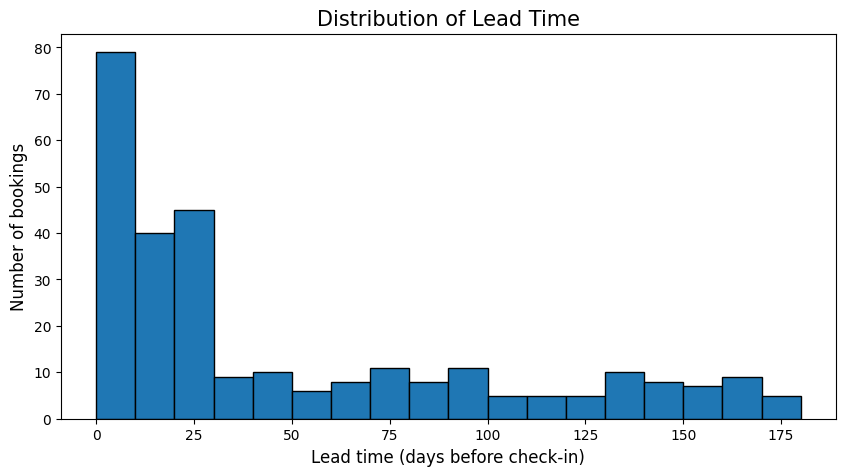

30일 이내 예약 비율(%): 60.1


In [259]:
plt.figure(figsize=(10, 5))

plt.hist(booking_clean['lead_time'], bins=range(0, 190, 10), edgecolor='black')

plt.title('Distribution of Lead Time', fontsize=15)
plt.xlabel('Lead time (days before check-in)', fontsize=12)
plt.ylabel('Number of bookings', fontsize=12)
plt.show()
print('30일 이내 예약 비율(%):', round((booking_clean['lead_time'] <= 30).mean() * 100, 1))

예약은 입실 0~10일 전 구간에 가장 많이 몰려 있고(79건), 30일 이내 예약이 전체의 약 60%다. 30일 이후 예약은 수가 적지만 최대 179일 전까지 길게 퍼져 있다.

In [260]:
channel_table = booking_clean.groupby('booking_channel')['is_canceled'].agg(['count', 'sum'])
channel_table.columns = ['예약 건수', '취소 건수']
channel_table['취소율(%)'] = (channel_table['취소 건수'] / channel_table['예약 건수'] * 100).round(1)

channel_table

,예약 건수,취소 건수,취소율(%)
booking_channel,,,
Agency,53,9,17.0
Direct,83,13,15.7
Online,141,42,29.8
Unknown,4,1,25.0


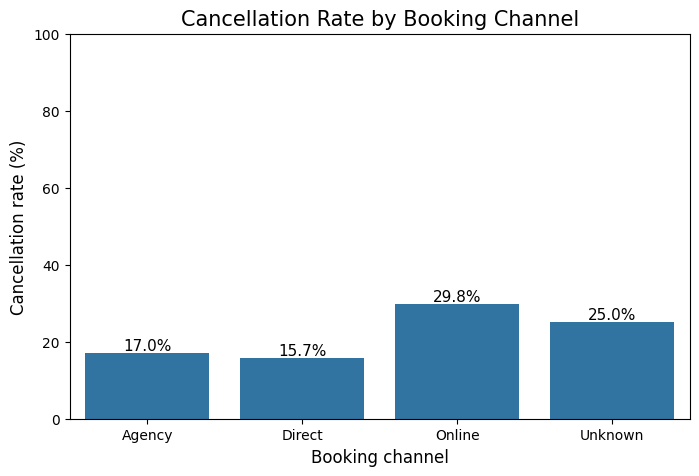

In [261]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(x=channel_table.index, y=channel_table['취소율(%)'])

ax.set_title('Cancellation Rate by Booking Channel', fontsize=15)
ax.set_xlabel('Booking channel', fontsize=12)
ax.set_ylabel('Cancellation rate (%)', fontsize=12)

ax.set_ylim(0, 100)
ax.bar_label(ax.containers[0], fmt='%.1f%%', fontsize=11)

plt.show()

기준 시점의 관측 취소율은 Online이 29.8%(141건 중 42건)로 가장 높고, Agency 17.0%, Direct 15.7% 순이다. Unknown은 25.0%지만 4건 중 1건이라 해석에 주의가 필요하며, 이 차이만으로 온라인 예약이 취소를 일으킨다고 단정할 수는 없다.

                 예약 건수  취소 건수  취소율(%)
lead_time_group                      
Within7Days         69     12    17.4
8to30Days          100     13    13.0
Over30Days         112     40    35.7


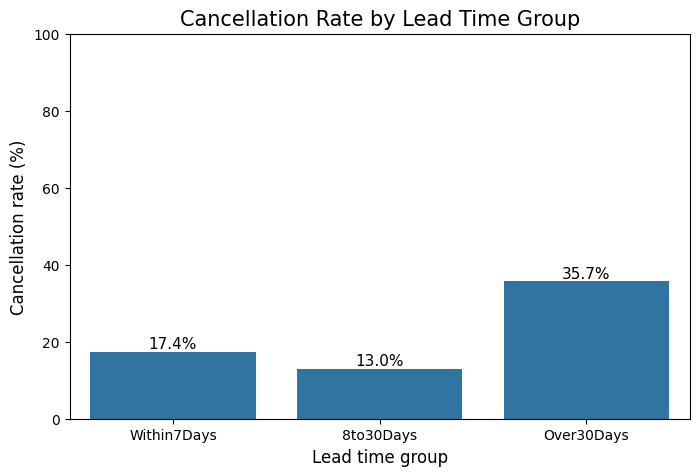

In [262]:
# (1) 표 먼저
group_table = booking_clean.groupby('lead_time_group', observed=False)['is_canceled'].agg(['count', 'sum'])
group_table.columns = ['예약 건수', '취소 건수']
group_table['취소율(%)'] = (group_table['취소 건수'] / group_table['예약 건수'] * 100).round(1)
print(group_table)

# (2) 막대그래프
plt.figure(figsize=(8, 5))

ax = sns.barplot(x=group_table.index, y=group_table['취소율(%)'],
                 order=["Within7Days", "8to30Days", "Over30Days"])

ax.set_title('Cancellation Rate by Lead Time Group', fontsize=15)
ax.set_xlabel('Lead time group', fontsize=12)
ax.set_ylabel('Cancellation rate (%)', fontsize=12)
ax.set_ylim(0, 100)
ax.bar_label(ax.containers[0], fmt='%.1f%%', fontsize=11)

plt.show()

기준 시점의 관측 취소율은 입실 30일 초과 전에 한 예약이 35.7%(112건 중 40건)로 가장 높고, 7일 이내 17.4%, 8~30일 13.0% 순이다. 예약이 오래전에 이뤄질수록 취소할 시간이 길다는 점도 함께 고려해야 하며, 이 결과만으로 선행일수가 취소의 원인이라고 단정할 수는 없다.

# 문제 7. 예약 운영팀에 분석 결과 전달

**데이터 정리**
원본 300건 중 일수·인원수가 음수인 5건과 요금이 0원 이하인 2건은 입력 오류로 보고 빈 값으로 바꿨습니다. 그다음 일수·인원수가 비어 있는 15건과 숙박일수나 인원이 0인 4건을 빼고, 남은 281건으로 분석했습니다. 비어 있던 요금은 중앙값인 12만 원으로 채웠고, 객실 유형과 예약 경로는 'Unknown'으로 표시했습니다.

**예약과 취소**
예약의 약 60%는 입실 30일 이내에 들어왔고, 취소율은 온라인 예약(29.8%)과 입실 30일보다 앞서 잡은 예약(35.7%)에서 가장 높았습니다.

**사전 확인 대상**
운영팀 기준에 맞는 예약은 35건이고, 예상 객실 요금은 모두 합해 2,151만 원입니다.

**제안**
이 중 금액이 가장 큰 HB0028(192만 원)은 객실 유형이 비어 있어서, 실제 어떤 객실인지 먼저 확인해 보면 좋겠습니다.

**한계**
다만 교육용 가상 데이터이고 취소율도 지금 시점 기준이라 원인으로 단정하기는 어려우며, 취소 시점과 환불 내역이 있으면 매출에 미치는 영향까지 더 정확히 볼 수 있습니다.